In [314]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

# Reading and Exploring the features

- handling duplicates and nulls 
- converting some `str` columns into numerical ones [`PostedDate`, `AskPrice`, `kmDriven`]

In [315]:
used_cars_df = pd.read_csv('../used-car-dataset/used_cars_dataset_v2.csv')
used_cars_df 

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,"31,000 km",Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...","₹ 5,75,000"
14989,BMW,X1,2017,7,"45,000 km",Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel","₹ 13,45,000"
14990,Maruti Suzuki,New-gen Swift,2011,13,"60,000 km",Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,"₹ 1,60,000"
14991,Tata,Zest,2019,5,"62,000 km",Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids","₹ 3,80,000"


In [316]:
used_cars_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         14993 non-null  str  
 1   model         14993 non-null  str  
 2   Year          14993 non-null  int64
 3   Age           14993 non-null  int64
 4   kmDriven      14905 non-null  str  
 5   Transmission  14993 non-null  str  
 6   Owner         14993 non-null  str  
 7   FuelType      14993 non-null  str  
 8   PostedDate    14993 non-null  str  
 9   AdditionInfo  14993 non-null  str  
 10  AskPrice      14993 non-null  str  
dtypes: int64(2), str(9)
memory usage: 1.3 MB


In [317]:
used_cars_df.isna().mean() * 100

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.586941
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
dtype: float64

In [318]:
print("Count of duplicates :", used_cars_df.duplicated().sum())
print(f'Percentage of duplicates : {used_cars_df.duplicated().mean()*100:.2f}%')

Count of duplicates : 997
Percentage of duplicates : 6.65%


In [319]:
used_cars_df.drop_duplicates(inplace=True)
used_cars_df.dropna(inplace=True)

In [320]:
used_cars_df.isna().sum()

Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
PostedDate      0
AdditionInfo    0
AskPrice        0
dtype: int64

In [321]:
used_cars_df.duplicated().mean()*100

np.float64(0.0)

In [322]:
val_unit_kmDriven = used_cars_df['kmDriven'].str.split()
val_unit_kmDriven.str[1].value_counts()

kmDriven
km    13909
Name: count, dtype: int64

In [323]:
currency_price_AskPrice = used_cars_df['AskPrice'].str.split()
currency_price_AskPrice.str[0].value_counts()

AskPrice
₹    13909
Name: count, dtype: int64

In [324]:
used_cars_df['kmDriven'] = used_cars_df['kmDriven'].str.replace(r'[^\d.]', '',regex=True).astype(float)
used_cars_df['AskPrice'] = used_cars_df['AskPrice'].str.replace(r'[^\d.]', '', regex=True).astype(float)

In [325]:
used_cars_df['postedMonth'] = used_cars_df['PostedDate'].str.replace(r'[\d-]', '', regex=True)
used_cars_df['postedYear'] = used_cars_df['PostedDate'].str.replace(r'[\D]', '', regex=True).astype(int)
used_cars_df['postedYear'] = used_cars_df['postedYear'] + 2000


In [326]:
month_format = used_cars_df['postedMonth'].value_counts().index.tolist()
month_format

['Nov',
 'Dec',
 'Oct',
 'Sep',
 'Aug',
 'Jul',
 'Jun',
 'Apr',
 'May',
 'Jan',
 'Feb',
 'Mar']

In [327]:
month_format = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep','Oct', 'Nov','Dec']
dict={}

for i in range(len(month_format)):
    dict[month_format[i]] = i+1

used_cars_df['postedMonth'] = used_cars_df['postedMonth'].map(dict)


In [328]:
used_cars_df[['PostedDate','postedMonth','postedYear']]

,PostedDate,postedMonth,postedYear
0,Nov-24,11,2024
1,Jul-24,7,2024
2,Nov-24,11,2024
3,Nov-24,11,2024
4,Nov-24,11,2024
...,...,...,...
14988,Nov-24,11,2024
14989,Dec-24,12,2024
14990,Nov-24,11,2024
14991,Nov-24,11,2024


In [329]:
used_cars_df[['kmDriven', 'AskPrice']]

,kmDriven,AskPrice
0,98000.0,195000.0
1,190000.0,375000.0
2,77246.0,184999.0
3,83500.0,565000.0
4,45000.0,685000.0
...,...,...
14988,31000.0,575000.0
14989,45000.0,1345000.0
14990,60000.0,160000.0
14991,62000.0,380000.0


In [330]:
used_cars_df.drop_duplicates(inplace=True)

In [331]:
used_cars_df.info()

<class 'pandas.DataFrame'>
Index: 13898 entries, 0 to 14992
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13898 non-null  str    
 1   model         13898 non-null  str    
 2   Year          13898 non-null  int64  
 3   Age           13898 non-null  int64  
 4   kmDriven      13898 non-null  float64
 5   Transmission  13898 non-null  str    
 6   Owner         13898 non-null  str    
 7   FuelType      13898 non-null  str    
 8   PostedDate    13898 non-null  str    
 9   AdditionInfo  13898 non-null  str    
 10  AskPrice      13898 non-null  float64
 11  postedMonth   13898 non-null  int64  
 12  postedYear    13898 non-null  int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 1.5 MB


In [332]:
used_cars_df[['Brand', 'model', 'Year', 'AdditionInfo']]

,Brand,model,Year,AdditionInfo
0,Honda,City,2001,"Honda City v teck in mint condition, valid gen..."
1,Toyota,Innova,2009,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D..."
2,Volkswagen,VentoTest,2010,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010..."
3,Maruti Suzuki,Swift,2017,Maruti Suzuki Swift 2017 Diesel Good Condition
4,Maruti Suzuki,Baleno,2019,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol"
...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ..."
14989,BMW,X1,2017,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel"
14990,Maruti Suzuki,New-gen Swift,2011,Bahut badhiya new condition
14991,Tata,Zest,2019,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids"


In [333]:
def extract_info(d):
    t = d["AdditionInfo"].fillna("").str.lower()
    t_nofuel = t.str.replace(r"cng & hy\w*\.*", "", regex=True)  # drop scraped suffix
    out = pd.DataFrame(index=d.index)
    out["engine_l"]  = t.str.extract(r"(?<![\d.])(\d\.\d{1,2})(?!\d)(?!\s*(?:marla|lakh|lac))")[0].astype(float)
    out["seats"]     = t.str.extract(r"(\d)[\s-]*(?:seater|seats?|str)\b")[0].astype(float)
    out["is_4wd"]    = t.str.contains(r"4\s?x\s?4|4wd|\bawd\b|xdrive|4matic|quattro|4motion").astype(int)
    out["cng_in_text"] = t_nofuel.str.contains(r"\bcng\b").astype(int)
    out["is_top"]    = t.str.contains(r"top[\s-]*(?:model|end|variant|varient)|fully loaded|full option").astype(int)
    out["well_kept"] = t.str.contains(r"well[\s-]*(?:maintained|kept)|\bmint\b|good condition|excellent|like new").astype(int)
    return out


df_copy = used_cars_df.copy()
df_copy = df_copy.join(extract_info(used_cars_df))
df_copy

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,seats,is_4wd,cng_in_text,is_top,well_kept
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,11,2024,NaN,NaN,0,0,0,1
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,7,2024,2.5,7.0,0,0,0,0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,11,2024,NaN,NaN,0,0,0,0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,11,2024,NaN,NaN,0,0,0,1
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,11,2024,NaN,NaN,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,31000.0,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,11,2024,NaN,NaN,0,1,0,0
14989,BMW,X1,2017,7,45000.0,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,12,2024,2.0,NaN,0,0,0,0
14990,Maruti Suzuki,New-gen Swift,2011,13,60000.0,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11,2024,NaN,NaN,0,0,0,0
14991,Tata,Zest,2019,5,62000.0,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,11,2024,1.2,NaN,0,0,0,0


Baseline RMSE (log-price): 0.3358 ± 0.0186


,% rows with info,spearman vs log(price),RMSE gain,± SE,gain / SE,decision
column,,,,,,
engine_l,35.0,0.647,0.0224,0.0008,27.8,KEEP
is_4wd,3.5,0.244,0.0007,0.0002,3.4,DROP
seats,3.4,0.120,0.0005,0.0004,1.4,DROP
cng_in_text,6.1,-0.086,0.0004,0.0003,1.2,DROP
well_kept,8.2,-0.119,0.0001,0.0004,0.4,DROP
is_top,0.4,0.009,-0.0002,0.0001,-2.2,DROP


baseline                                      RMSE = 0.3358 ± 0.0186
chosen ['engine_l']                           RMSE = 0.3134 ± 0.0172
all candidates                                RMSE = 0.3125 ± 0.0172


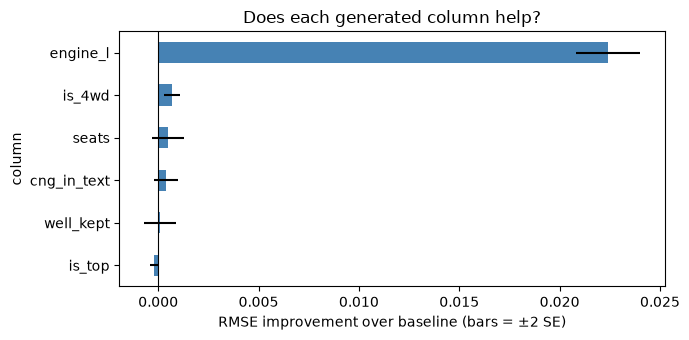

In [334]:
# ── Which generated column deserves to be kept? ──────────────────────────────
from sklearn.model_selection import RepeatedKFold, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import BaseEstimator, TransformerMixin

class EngineFill(BaseEstimator, TransformerMixin):
    """Fill missing engine_l with the median of the same brand_model, then the same Brand, then overall.
    Medians are learned from the training part of each fold only (no leakage)."""
    def fit(self, X, y=None):
        self.by_bm, self.by_brand, self.med = (X.groupby("brand_model")["engine_l"].median(),
                                              X.groupby("Brand")["engine_l"].median(),
                                              X["engine_l"].median())
        return self
    def transform(self, X):
        X = X.copy()
        X["engine_l"] = (X["engine_l"].fillna(X["brand_model"].map(self.by_bm))
                                      .fillna(X["Brand"].map(self.by_brand))
                                      .fillna(self.med))
        return X

candidates = ["engine_l", "seats", "is_4wd", "cng_in_text", "is_top", "well_kept"]

# ---------- data used for the test (the generated columns come from df_copy) ----------
X_all = df_copy.copy()
X_all["brand_model"] = X_all["Brand"].astype(str) + "|" + X_all["model"].astype(str)
X_all["km_log"]      = np.log1p(X_all["kmDriven"])
X_all["owner_ord"]   = X_all["Owner"].map({"first": 1, "second": 2, "third": 3, "fourth": 4, "fifth": 5})
y = np.log1p(X_all["AskPrice"])                       # log target: price is heavily skewed

base_num = ["Age", "km_log", "owner_ord"]

def make_model(extra):
    pre = ColumnTransformer([
        ("bm", TargetEncoder(cv=KFold(n_splits=5, shuffle=True, random_state=0)), ["brand_model"]),   # fitted inside each fold -> no leakage
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Transmission", "FuelType"]),
        ("num", "passthrough", base_num + extra),
    ])
    # seats keeps its NaNs (HistGradientBoosting handles NaN natively); engine_l is filled inside each fold
    return Pipeline([("fill", EngineFill()), ("pre", pre),
                     ("reg", HistGradientBoostingRegressor(random_state=0))])

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)   # identical splits for every run -> paired comparison

def cv_scores(extra):
    return -cross_val_score(make_model(extra), X_all, y, cv=cv, scoring="neg_root_mean_squared_error")

base = cv_scores([])

# ---------- one row per candidate ----------
rows = []
for c in candidates:
    s      = X_all[c]
    delta  = base - cv_scores([c])                     # >0 means the column LOWERED the error
    gain   = delta.mean()
    se     = delta.std(ddof=1) / np.sqrt(len(delta))
    pres   = s.notna().mean() * 100 if c in ("engine_l", "seats") else (s == 1).mean() * 100
    rho    = s.corr(y, method="spearman")
    rows.append({
        "column": c,
        "% rows with info": round(pres, 1),            # non-null % for numeric, % of 1s for flags
        "spearman vs log(price)": round(rho, 3),
        "RMSE gain": round(gain, 4),
        "± SE": round(se, 4),
        "gain / SE": round(gain / se, 1) if se > 0 else np.nan,
    })

res = pd.DataFrame(rows).set_index("column")

# ---------- decision rule (written down in advance) ----------
def verdict(r):
    if r["RMSE gain"] > 0.005 and r["gain / SE"] > 3:   return "KEEP"
    if r["RMSE gain"] > 0.001 and r["gain / SE"] > 2:   return "MAYBE (small)"
    return "DROP"

res["decision"] = res.apply(verdict, axis=1)
res = res.sort_values("RMSE gain", ascending=False)

print(f"Baseline RMSE (log-price): {base.mean():.4f} ± {base.std():.4f}")
display(res)

# ---------- final check: chosen set vs baseline vs everything ----------
chosen = res.index[res["decision"] == "KEEP"].tolist()
for name, cols in {"baseline": [], f"chosen {chosen}": chosen, "all candidates": candidates}.items():
    s = cv_scores(cols)
    print(f"{name:45s} RMSE = {s.mean():.4f} ± {s.std():.4f}")

# ---------- plot ----------
ax = res["RMSE gain"].plot.barh(xerr=res["± SE"] * 2, figsize=(7, 3.5), color="steelblue")
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("RMSE improvement over baseline (bars = ±2 SE)")
ax.set_title("Does each generated column help?")
plt.tight_layout(); plt.show()

In [335]:
df_copy.isna().mean()*100

Brand            0.000000
model            0.000000
Year             0.000000
Age              0.000000
kmDriven         0.000000
Transmission     0.000000
Owner            0.000000
FuelType         0.000000
PostedDate       0.000000
AdditionInfo     0.000000
AskPrice         0.000000
postedMonth      0.000000
postedYear       0.000000
engine_l        64.966182
seats           96.639804
is_4wd           0.000000
cng_in_text      0.000000
is_top           0.000000
well_kept        0.000000
dtype: float64

In [336]:
used_cars_df['engine_l'] = df_copy['engine_l']

In [337]:
used_cars_df.isna().mean()

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.000000
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
postedMonth     0.000000
postedYear      0.000000
engine_l        0.649662
dtype: float64

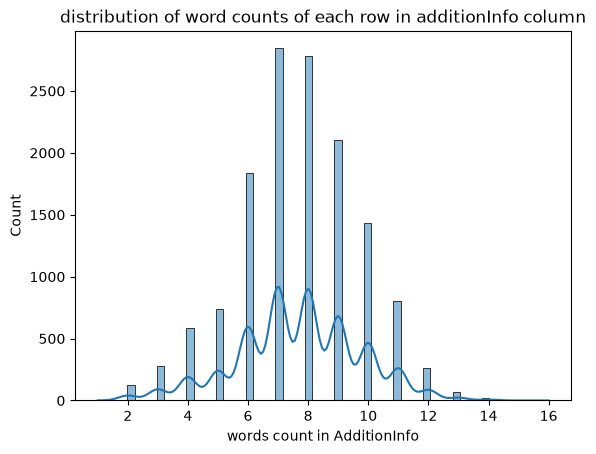

In [338]:
plt.subplots()
sns.histplot(data=pd.DataFrame(used_cars_df['AdditionInfo'].str.split().map(lambda x: len(x))),
             x='AdditionInfo',
             kde=True)

plt.title('distribution of word counts of each row in additionInfo column')
plt.xlabel('words count in AdditionInfo')
plt.ylabel('Count')
plt.show()

# Explortary Data Analysis **EDA** 

#### Categorical distributions and Exploration

In [347]:
used_cars_df.info()

<class 'pandas.DataFrame'>
Index: 13898 entries, 0 to 14992
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13898 non-null  str    
 1   model         13898 non-null  str    
 2   Year          13898 non-null  int64  
 3   Age           13898 non-null  int64  
 4   kmDriven      13898 non-null  float64
 5   Transmission  13898 non-null  str    
 6   Owner         13898 non-null  str    
 7   FuelType      13898 non-null  str    
 8   PostedDate    13898 non-null  str    
 9   AdditionInfo  13898 non-null  str    
 10  AskPrice      13898 non-null  float64
 11  postedMonth   13898 non-null  int64  
 12  postedYear    13898 non-null  int64  
 13  engine_l      4869 non-null   float64
 14  brand_model   13898 non-null  str    
dtypes: float64(3), int64(4), str(8)
memory usage: 1.7 MB


In [348]:
used_cars_df['brand_model'] = used_cars_df['Brand'] + ',' + used_cars_df['model']
display("preview of the new concatenated column")
display(used_cars_df[['brand_model', 'Brand', 'model']].head(10))
display('New unique counts in brand_model column')
display(used_cars_df[['brand_model', 'Brand', 'model']].nunique())

'preview of the new concatenated column'

,brand_model,Brand,model
0,"Honda,City",Honda,City
1,"Toyota,Innova",Toyota,Innova
2,"Volkswagen,VentoTest",Volkswagen,VentoTest
3,"Maruti Suzuki,Swift",Maruti Suzuki,Swift
4,"Maruti Suzuki,Baleno",Maruti Suzuki,Baleno
5,"BMW,X3",BMW,X3
6,"Toyota,Innova",Toyota,Innova
7,"BMW,5 Series",BMW,5 Series
8,"Maruti Suzuki,maruti-suzuki-dzire",Maruti Suzuki,maruti-suzuki-dzire
9,"Ford,Ecosport",Ford,Ecosport


'New unique counts in brand_model column'

brand_model    435
Brand           42
model          434
dtype: int64

In [349]:
temp = used_cars_df.drop_duplicates(subset='brand_model')
mask = temp.duplicated(subset='model', keep=False).tolist()

temp[mask] # Mahindra <- Ssangyon & the Rexton was common between them

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model
6685,Mahindra,Rexton,2015,9,57000.0,Automatic,second,Diesel,Nov-24,"Mahindra Rexton, 2015, Diesel",799000.0,11,2024,NaN,"Mahindra,Rexton"
7772,Ssangyong,Rexton,2013,11,120000.0,Automatic,second,Diesel,Nov-24,"Ssangyong Rexton RX7, 2013, Diesel",240000.0,11,2024,NaN,"Ssangyong,Rexton"


In [350]:
cat_cols = used_cars_df.drop(columns=['AdditionInfo', 'PostedDate']).select_dtypes(include='str').columns.tolist()
cat_cols

['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'brand_model']

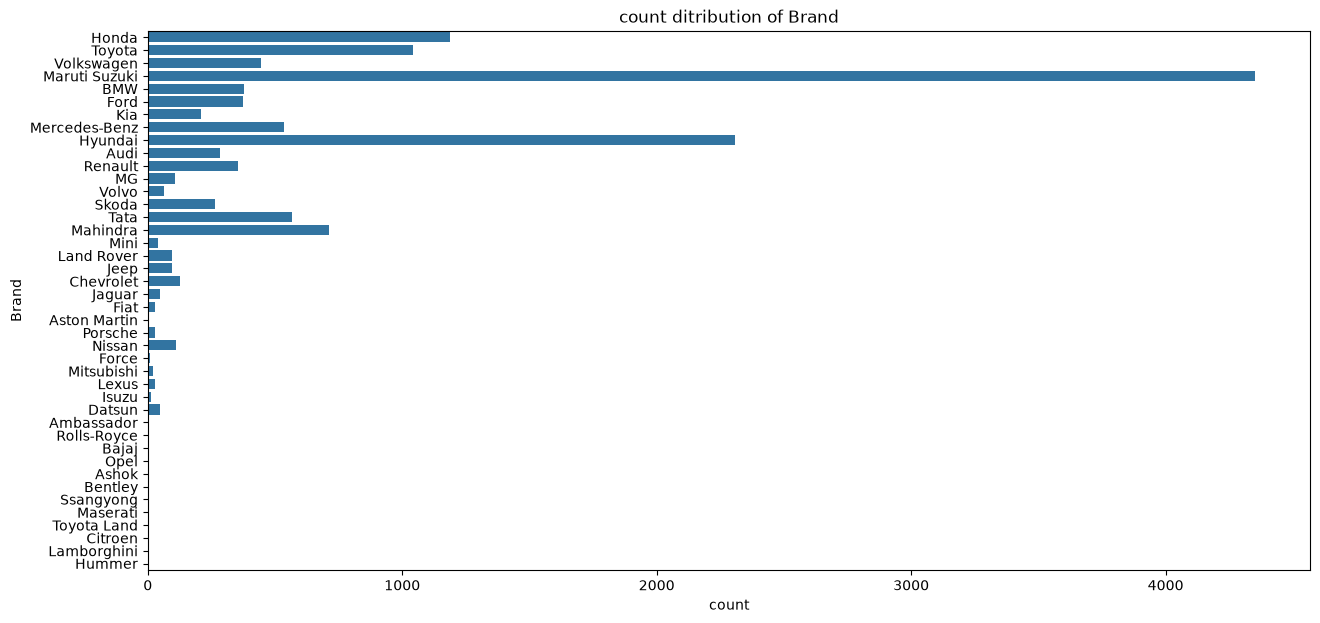

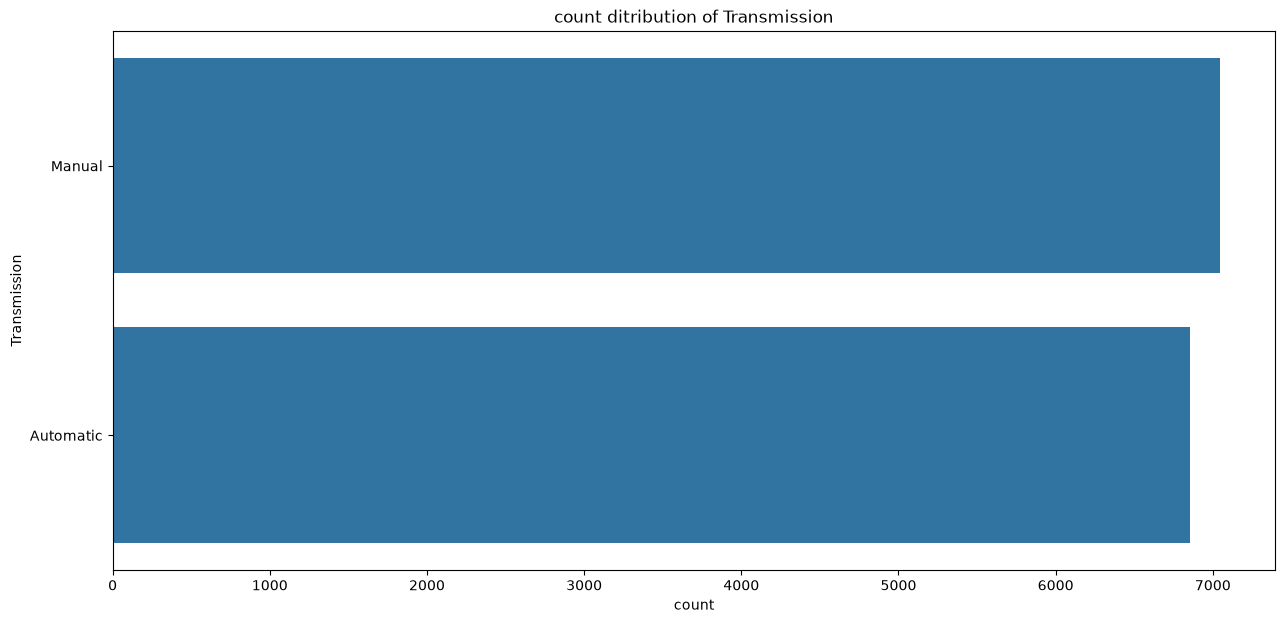

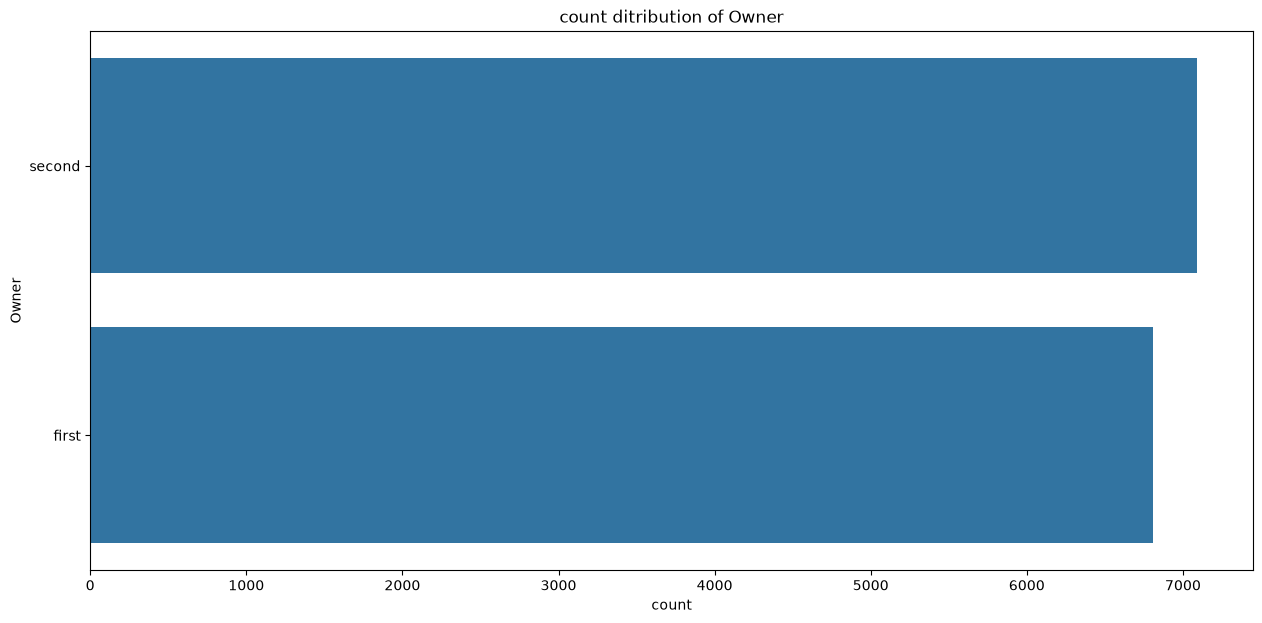

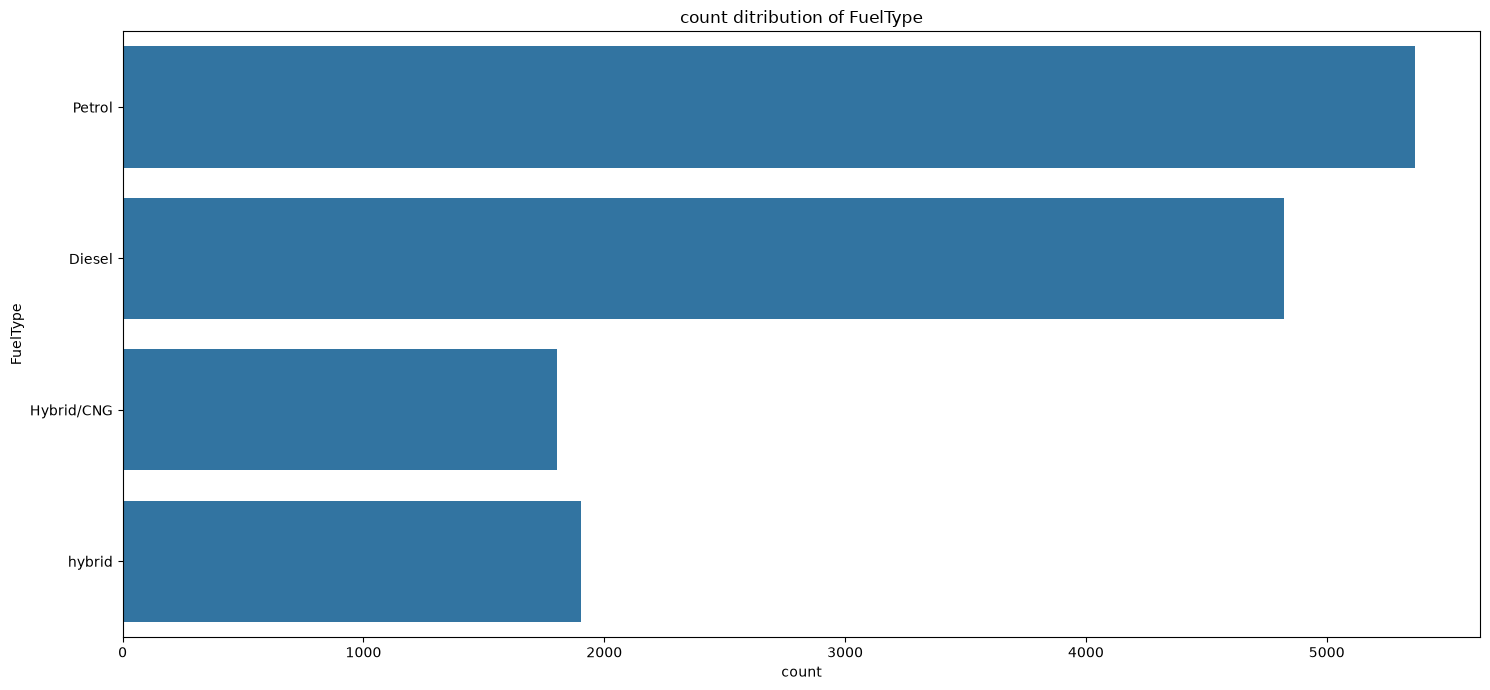

In [351]:
for col in cat_cols:
    if col == 'model' or col == 'brand_model': 
        continue
    plt.figure(figsize=(15,7))
    sns.countplot(data=used_cars_df, y=col)
    plt.title(f'count ditribution of {col}')

plt.tight_layout()
plt.show()


In [352]:
for col in cat_cols:
    if col == 'model':
        continue
    top10_count = used_cars_df[col].value_counts().sort_values(ascending=False).head(10).index.tolist() 
    print(f'top 10 counts in {col} -descending- :\n', top10_count)


top 10 counts in Brand -descending- :
 ['Maruti Suzuki', 'Hyundai', 'Honda', 'Toyota', 'Mahindra', 'Tata', 'Mercedes-Benz', 'Volkswagen', 'BMW', 'Ford']
top 10 counts in Transmission -descending- :
 ['Manual', 'Automatic']
top 10 counts in Owner -descending- :
 ['second', 'first']
top 10 counts in FuelType -descending- :
 ['Petrol', 'Diesel', 'hybrid', 'Hybrid/CNG']
top 10 counts in brand_model -descending- :
 ['Maruti Suzuki,Wagon-R', 'Honda,City', 'Maruti Suzuki,Ertiga', 'Maruti Suzuki,Swift', 'Maruti Suzuki,Swift-Dzire', 'Hyundai,Creta', 'Maruti Suzuki,Celerio', 'Hyundai,i10', 'Maruti Suzuki,Eeco', 'Hyundai,Grand i10']


In [353]:
postedMonth = used_cars_df['PostedDate'].str.split('-').str[0]
postedMonth.value_counts()

PostedDate
Nov    12225
Dec      747
Oct      629
Sep      162
Aug       67
Jul       29
Jun       20
Apr        8
May        6
Jan        2
Feb        2
Mar        1
Name: count, dtype: int64

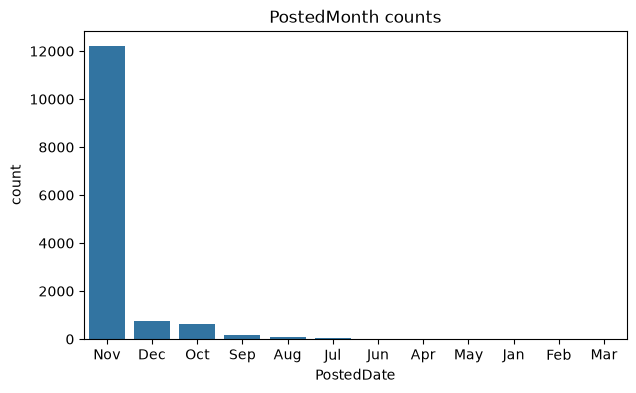

In [354]:
plt.figure(figsize=(7,4))
sns.barplot(postedMonth.value_counts())
plt.title('PostedMonth counts')
plt.show()

#### Categorical-Categorical relationships 

In [399]:
counts = used_cars_df.groupby(['Brand','model']).size().reset_index(name='count')
counts = counts.sort_values(by=['Brand', 'model'], ascending=[True, False])
counts.groupby('Brand').head(3) 

,Brand,model,count
0,Ambassador,Ambassador,3
1,Ashok,Leyland Stile,1
2,Aston Martin,Vanquish,1
16,Audi,RS7,1
15,Audi,Q7,28
...,...,...,...
423,Volkswagen,VentoTest,114
422,Volkswagen,Vento,22
434,Volvo,XC90,3
433,Volvo,XC60,19


In [ ]:
used_cars_df

#### Numerical distributions and Exploration

#### Numerical-Numerical relationships

#### Categorical-Numerical relationships